In [25]:


import json, math, warnings

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))
from common import paths, plots
from common.data import read_csv, show_dataset
from common.plots import (SUPERFICIE, TINTA, TINTA_2, PREDITO, enfeitar, plot_time_series)

plots.aplicar_estilo()



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = paths.RAW
IMG_DIR = paths.ROOT / 'docs' / 'figuras'

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
semente: 42


In [26]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee*.csv"))
)

print(f"{len(ARQUIVOS)} arquivos" + NL)

partes = []
for p in ARQUIVOS:
    df = read_csv(p)
    df['station'] = p.stem.split('_')[0]
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

9 arquivos

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [27]:

# remover colunas "mortas"
REMOVE_COLS = {"ano", 'velocidade_vento', 'condicao' }
raw = raw.drop(columns=[c for c in REMOVE_COLS if c in raw.columns])

df = show_dataset(
  raw
    .copy()
    .dropna(subset=['PCA'])
    .reset_index(drop=True)
) 


pool: 410375 linhas, 17 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9607


In [28]:
# Cleanup dataset
outages = (raw.PCA == 0) & (raw.ghit > 50)
clipping = (raw.PCA >= 1.95)
low_irradiance = (raw.ghit < 5)
high_temperature = (raw.temp_amb >= 50)

df = raw[~outages & ~clipping & ~low_irradiance & ~high_temperature].copy()

df = show_dataset(df.reset_index(drop=True))


pool: 396524 linhas, 17 colunas

nulos por coluna (so as que tem):
PCA    76

colunas com zero:
PCA    1057


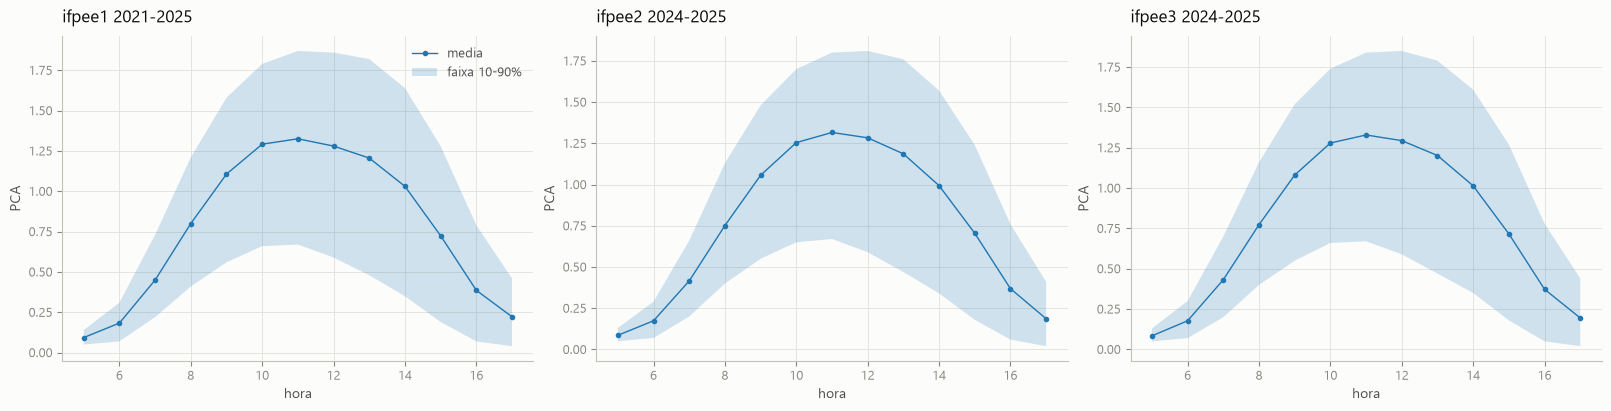

In [29]:
d2 = df.copy()

d2["hora"] = d2.datetime.dt.hour

# 1) PCA por hora do dia, uma estacao por painel (media + faixa 10-90%)
lines = (len(d2.station.unique()) / 2).__round__()
fig, axs = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    g = d.groupby("hora")["PCA"]
    ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
    ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                    alpha=0.2, label="faixa 10-90%")
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "hora", "PCA")
axs.flat[0].legend(frameon=False, fontsize=9, labelcolor=TINTA_2)
_ = fig.savefig(IMG_DIR / "pca_por_hora_do_dia.png")

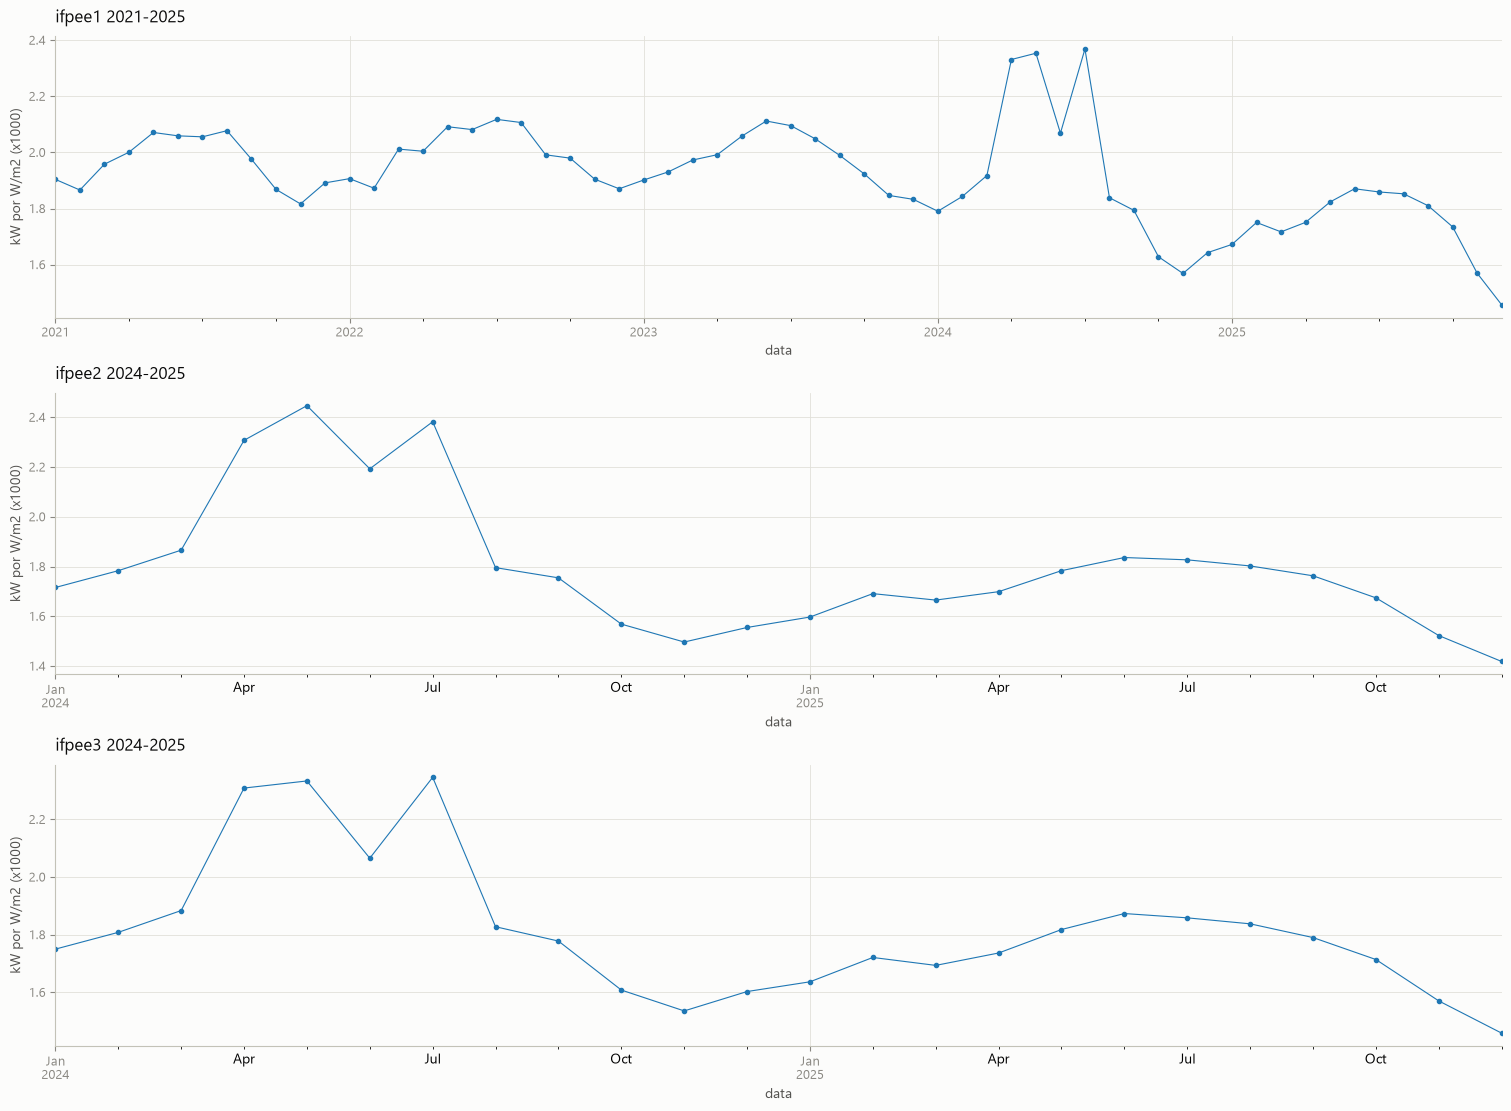

In [30]:
# 4) Eficiencia do sistema PCA / ghit (media diaria, x1000), uma estacao por painel.
# A razao cancela a sazonalidade de sol; o que sobra e' o estado do sistema.
fig, axs = plt.subplots(3, 1, figsize=(15, 11), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    dd = d[(d.PCA != 0) & (d.ghit > 0)]
    dd['ef'] = dd.PCA / dd.ghit
    dd = dd.groupby(dd["datetime"].dt.to_period("M")).agg({
        'ef': 'mean',
        'datetime': 'first'
    })
    ef = dd.ef
    (ef * 1000).plot(ax=ax, marker=".", lw=0.8)
    enfeitar(ax, f"{nome} {dd.datetime.dt.year.min()}-{dd.datetime.dt.year.max()}", "data", "kW por W/m2 (x1000)")
# fig.suptitle("Produtividade do sistema: PCA / ghit", color=TINTA, fontsize=13)
fig.savefig(IMG_DIR / "produtividade.png")
del d2

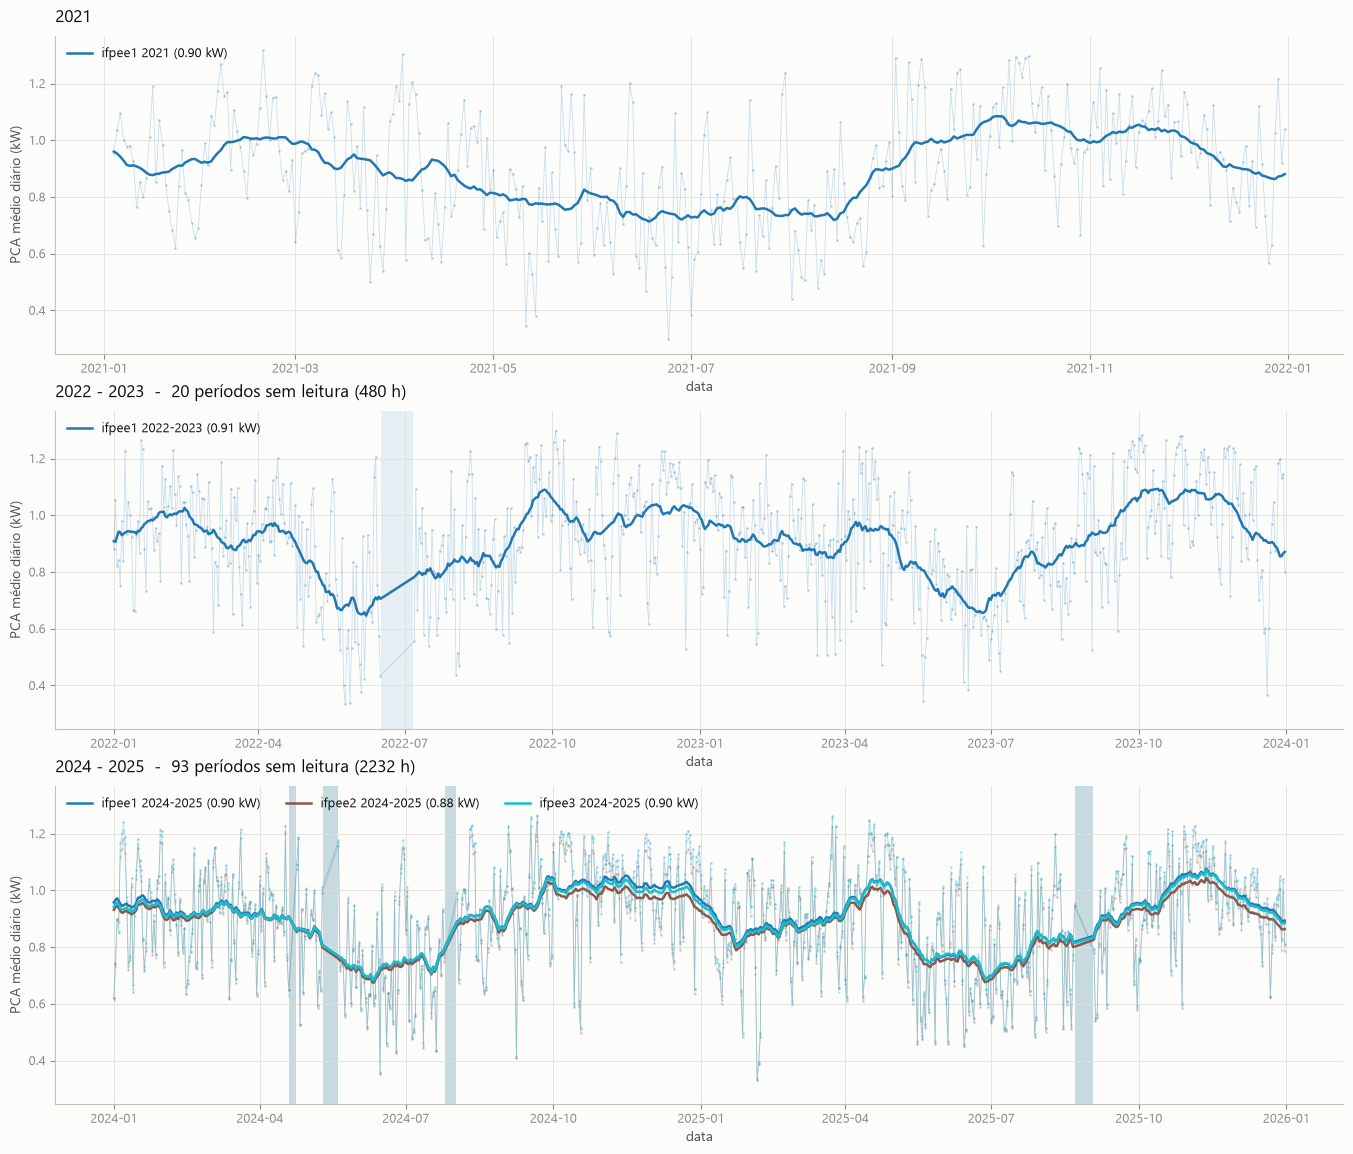

In [31]:
plot_time_series(df.reset_index(), janela='30d', freq="1D")


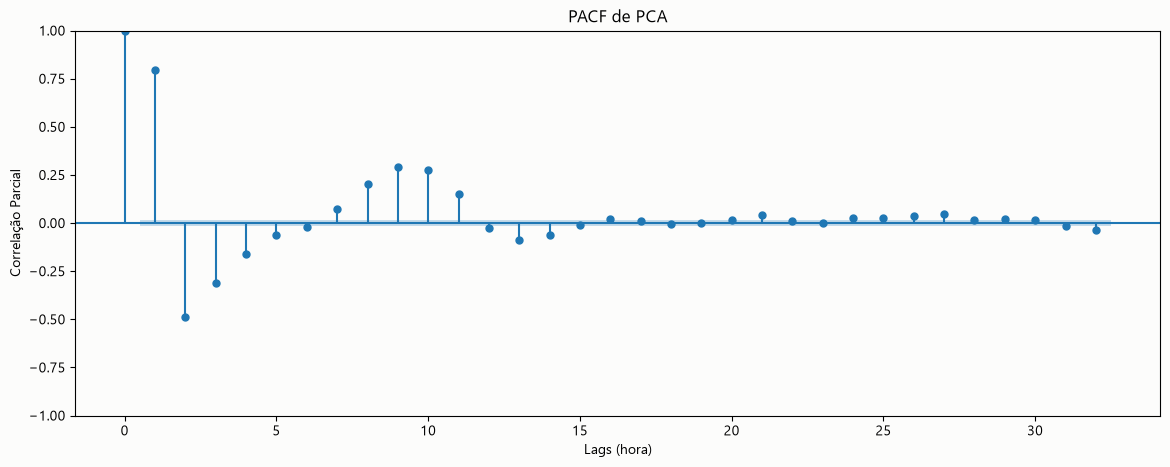

In [32]:
from statsmodels.graphics.tsaplots import plot_pacf

df_a = df.copy()  # remove 2024, que tem perda de dados
PCA = df_a.groupby([pd.Grouper(key='datetime', freq='1h')]).PCA.mean().dropna()


fig, ax = plt.subplots(figsize=(14, 5))
plot_pacf(PCA, ax=ax, lags=32, method="ywm", title="PACF de PCA")


# 3. Exibindo o gráfico
ax.set_xlabel("Lags (hora)")
ax.set_ylabel("Correlação Parcial")

plt.show()

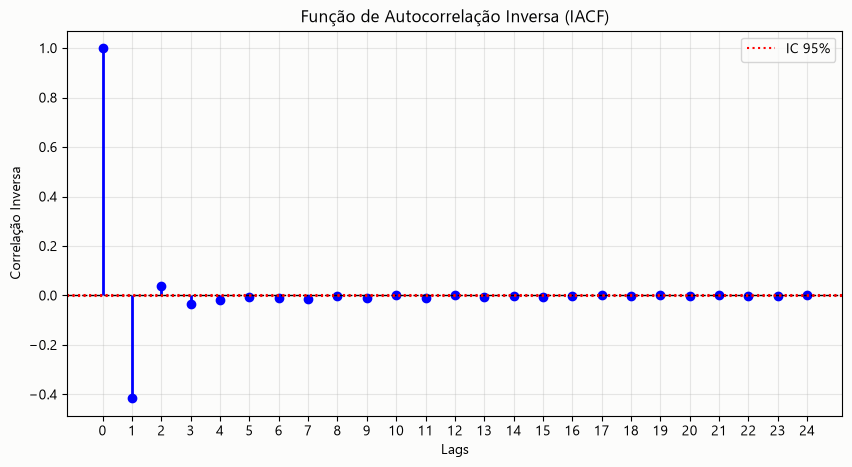

In [33]:
from statsmodels.regression.linear_model import yule_walker

def plot_iacf(series, lags=20):
    """
    Calcula e plota a Função de Autocorrelação Inversa (IACF)
    baseada na aproximação por um modelo autorregressivo de alta ordem.
    """
    # Remove valores nulos caso existam na série do Pandas
    series = series.dropna()
    n = len(series)
    
    # 1. Ajusta um modelo AR de alta ordem (Yule-Walker)
    # Geralmente usa-se a ordem sugerida pela metade das observações ou um limite prático
    ar_order = min(lags * 2, n // 3)
    ar_coefs, _ = yule_walker(series, order=ar_order, demean=True)
    
    # 2. Convoluciona os coeficientes AR com eles mesmos para obter a IACF aproximada
    # Adiciona 1 no início para representar o lag 0
    ar_operator = np.r_[1, -ar_coefs]
    iacf_raw = np.correlate(ar_operator, ar_operator, mode='full')
    
    # Pega apenas a metade positiva (lags de 0 em diante)
    iacf = iacf_raw[len(iacf_raw)//2 : len(iacf_raw)//2 + lags + 1]
    
    # Normaliza para que o lag 0 seja igual a 1
    iacf = iacf / iacf[0]

    # Remove lags muito baixos para evitar ruído visual (opcional)
    # iacf = np.where(np.abs(iacf) < 0.1, 0, iacf)
    
    # 3. Monta o gráfico no estilo clássico do statsmodels
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plota as barras verticais para os lags de 1 até o limite definido
    x_lags = np.arange(len(iacf))
    ax.vlines(x_lags, 0, iacf, colors='b', lw=2)
    ax.plot(x_lags, iacf, 'bo')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # Limites de significância estatística aproximados (IC de 95%)
    conf_level = 1.96 / np.sqrt(n)
    ax.axhline(conf_level, color='red', linestyle=':', label='IC 95%')
    ax.axhline(-conf_level, color='red', linestyle=':')
    
    ax.set_title("Função de Autocorrelação Inversa (IACF)")
    ax.set_xlabel("Lags")
    ax.set_ylabel("Correlação Inversa")
    ax.set_xticks(x_lags)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_iacf(df.PCA, lags=24)

In [34]:
import pandas as pd
def downsample(df: pd.DataFrame, interval: str):
    d = df.copy() 
    invalid = (
        (d.PCA == 0) | (d.ghit < 10) | 
        (d.temp_amb > 50) | 
        (d.PCA > 1.95)
    )
    d.drop(d[invalid].index, inplace=True)
    d = d.reset_index(drop=True)
    d = d.groupby(['datetime']).agg({'PCA': 'mean'})
    d = d[d.isna().sum(axis=1) == 0].reset_index()
    
    a = d.groupby(pd.Grouper(key="datetime", freq=interval))
    d = a.filter(lambda group: group["PCA"].ne(0).all())

    return d.groupby(pd.Grouper(key="datetime", freq=interval)).agg({'PCA': 'mean'})


In [35]:
intervals = ('5min', '10min', '30min', '1h', '6h', '1D')
frames = { interval: downsample(df, interval) for interval in intervals}

C:\Users\gusta\AppData\Local\Temp\ipykernel_18436\1855114184.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  d.drop(d[invalid].index, inplace=True)


C:\Users\gusta\AppData\Local\Temp\ipykernel_18436\3097727739.py:18: UserWarning: The figure layout has changed to tight
  fig.tight_layout(pad=3, h_pad=1.5)
C:\Users\gusta\AppData\Local\Temp\ipykernel_18436\3097727739.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


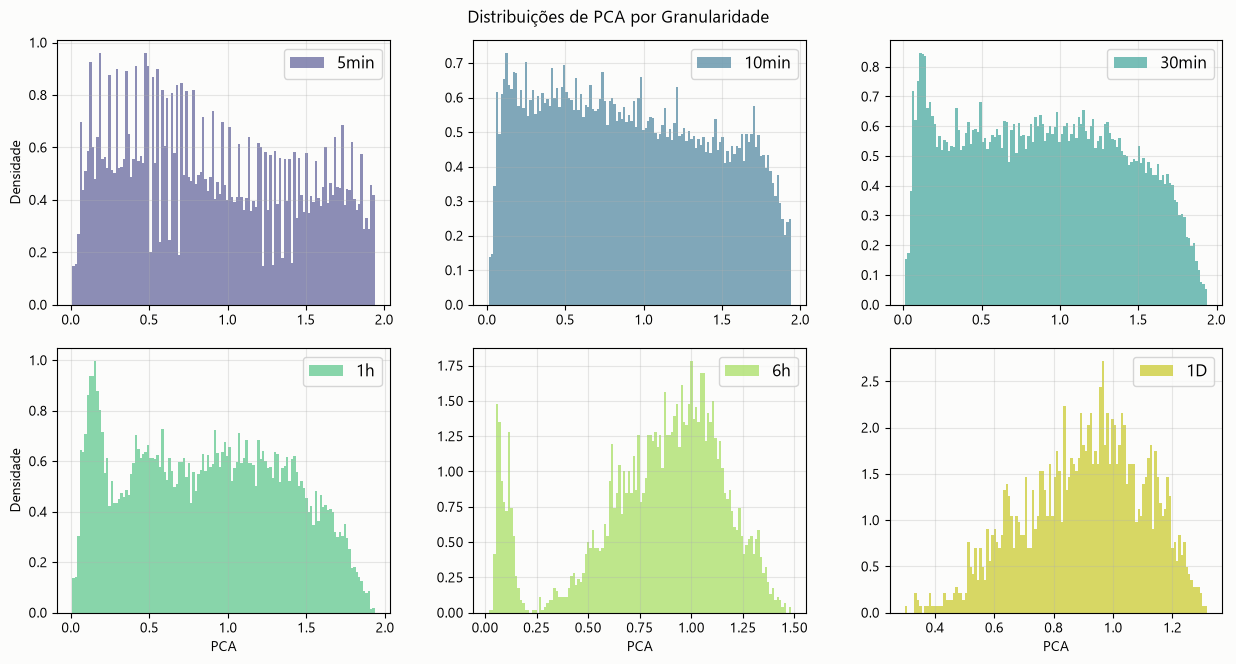

In [36]:
fig, ax = plt.subplots(figsize=(13, 7), ncols=3, nrows=2, constrained_layout=True)

cores = plt.cm.viridis(np.linspace(0.2, 1.0, 6)).tolist()
cores[-1] = 'y'

for freq, d2, ax, c in zip(intervals, frames.values(), ax.flat, cores):
  ax.hist(d2[d2.PCA > 0].PCA, bins=126, density=True, alpha=0.6, label=freq, color=c)
  ax.legend(loc="upper right", fontsize=12)
  
  if freq in intervals[3:]:
    ax.set_xlabel("PCA")

  if freq in (intervals[0], intervals[3]):
    ax.set_ylabel("Densidade")
  
  ax.grid(alpha=0.3)

fig.tight_layout(pad=3, h_pad=1.5)
fig.suptitle("Distribuições de PCA por Granularidade")
fig.show()

C:\Users\gusta\AppData\Local\Temp\ipykernel_18436\4193963325.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


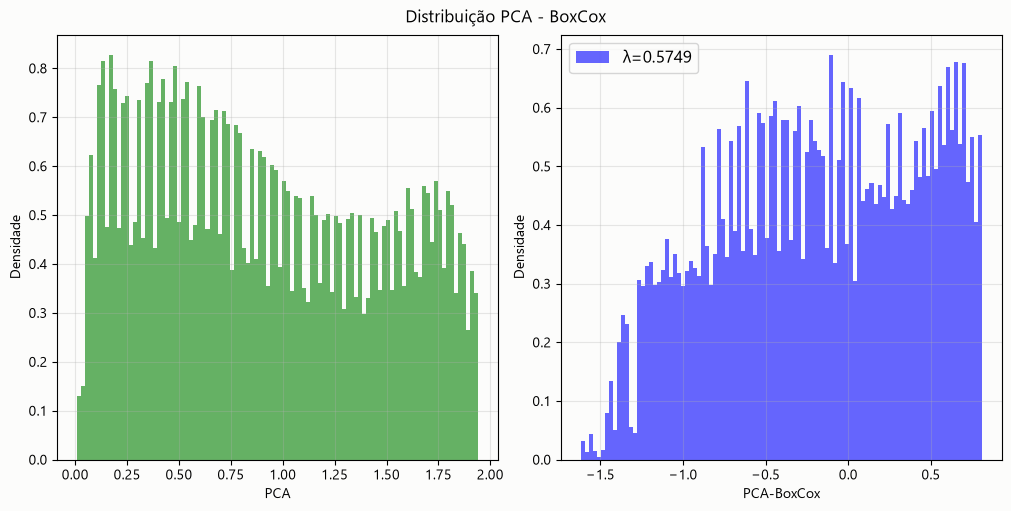

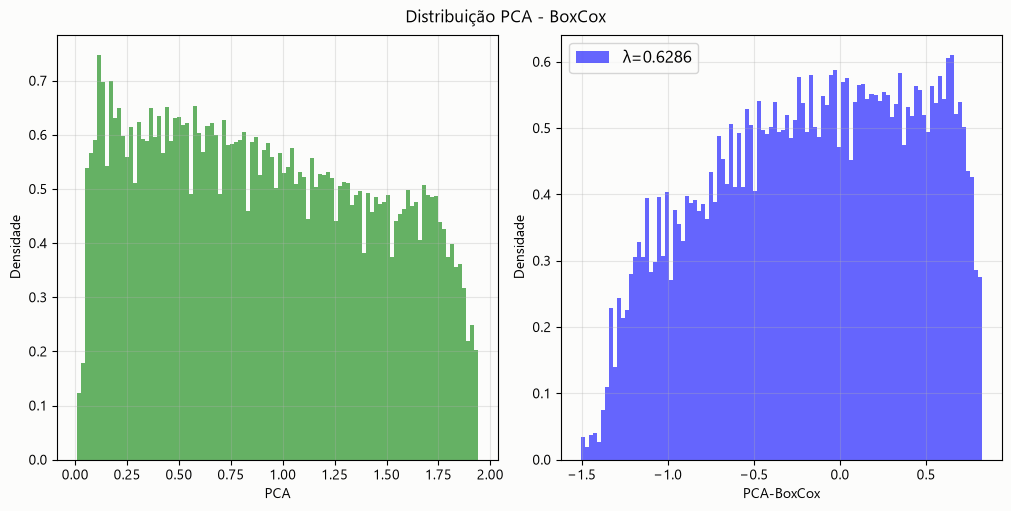

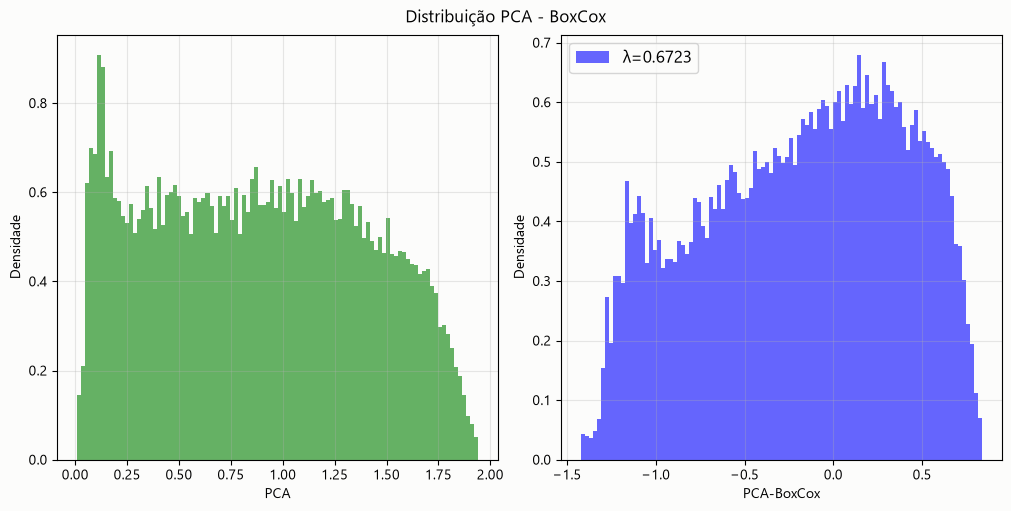

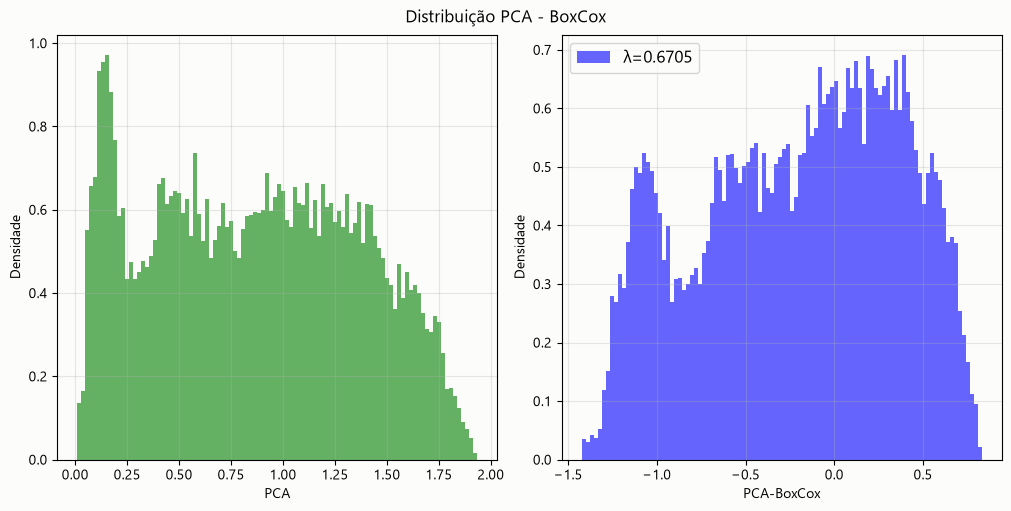

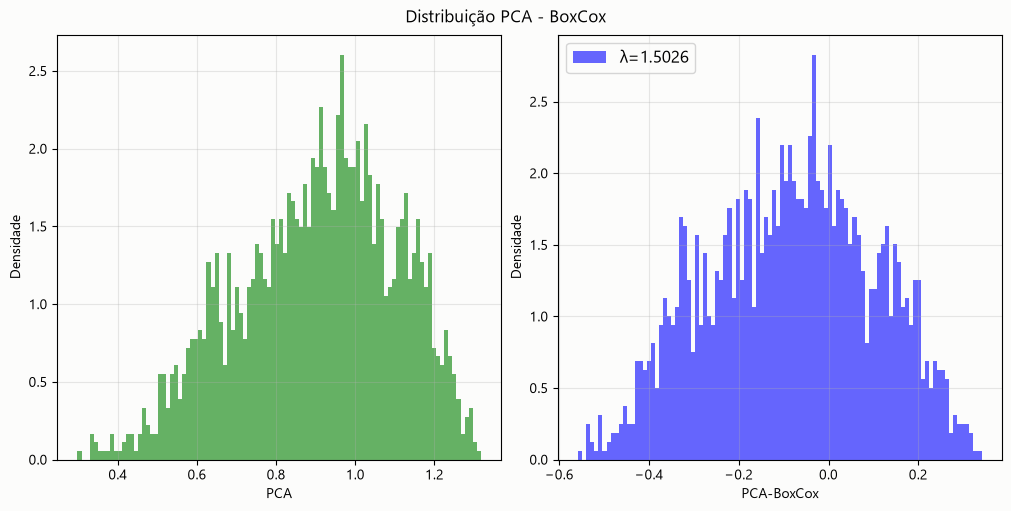

In [37]:
from scipy import stats

intervals2 = ('5min', '10min', '30min', '1h', '1D')

for freq, d2 in ((i, frames[i]) for i in intervals2):
    fig, ax = plt.subplots(figsize=(10, 5), ncols=2, constrained_layout=True)
    d2 = d2[d2.PCA > 0].reset_index(drop=True)
    d2['PCA-BoxCox'], lmbda = stats.boxcox(d2['PCA'])
    
    ax[0].hist(d2['PCA'], bins=100, density=True, alpha=0.6, color='g')
    ax[0].set_xlabel("PCA")
    ax[0].set_ylabel("Densidade")
    ax[0].grid(alpha=0.3)

    ax[1].hist(d2['PCA-BoxCox'], bins=100, label=f"λ={lmbda:.4f}", density=True, alpha=0.6, color='b')
    ax[1].legend(loc="upper left", fontsize=12)
    ax[1].set_xlabel("PCA-BoxCox")
    ax[1].set_ylabel("Densidade")
    ax[1].grid(alpha=0.3)
    fig.savefig(IMG_DIR / f"pca_boxcox_distribution_{freq}.png")
    fig.suptitle("Distribuição PCA - BoxCox")
    fig.show()

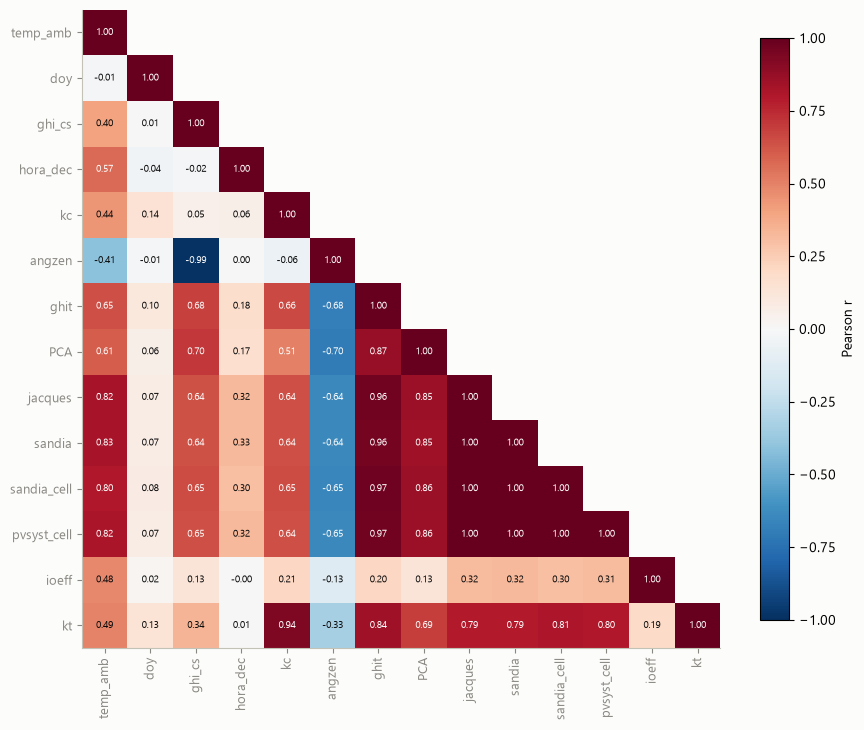

In [40]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=[np.number]).corr()
# heatmap da matriz de correlacao (so o triangulo inferior; a matriz e' simetrica)
n = len(corr_matrix)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_matrix.mask(mask).to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n), corr_matrix.columns, rotation=90)
ax.set_yticks(range(n), corr_matrix.index)
ax.set_aspect("equal")
enfeitar(ax, "", "", "")
ax.grid(False)

# anota o valor de Pearson dentro de cada celula
for r in range(n):
  for c in range(n):
    if c <= r:
      v = corr_matrix.iloc[r, c]
      ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
          color=SUPERFICIE if abs(v) > 0.5 else TINTA)

plt.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
plt.tight_layout()
plt.show()

In [39]:

numeric_cols = df.select_dtypes(include="number").columns

summary_stats = (
  df.groupby("station")[numeric_cols]
    .agg(["min", "max", "mean", "std"])
)

summary_stats

temp_amb                              doy                                  ghi_cs                                       hora_dec                                       kc                      \
             min     max       mean       std min  max        mean         std        min          max        mean         std       min        max       mean       std      min       max      mean   
station                                                                                                                                                                                                 
ifpee1     6.338  40.786  27.373295  4.136275   1  366  184.455338  107.671937  79.332931  1066.308609  657.586244  285.021967  5.779167  17.116667  11.462101  3.090805  0.00851  8.761781  0.764439   
ifpee2     6.338  40.786  27.685941  4.241224   1  366  184.081337  108.714716  79.332931  1066.308609  661.887964  285.683165  5.783333  17.116667  11.462832  3.073207  0.00851  8.761781  0.808337   
ifpee3     6.338  40.786  27.670263  4.241425   1  366  184.234172  108.707216  79.332931  1066.308609  660.533351  285.588584  5.783333  17.116667  11.458832  3.079029  0.00851  8.761781  0.807216   

                     angzen                                       ghit                                       PCA                              jacques                                      sandia  \
              std       min        max       mean        std       min          max        mean         std  min   max      mean       std        min        max       mean        std        min   
station                                                                                                                                                                                             
ifpee1   0.337045  0.159979  79.999981  44.610019  20.050915  5.015856  1583.257158  508.019517  329.705064  0.0  1.94  0.905205  0.548285  11.031228  75.964472  40.828021  11.985091  10.894606   
ifpee2   0.348397  0.134047  79.999951  44.266208  20.168296  5.016667  1583.257158  543.681134  350.573816  0.0  1.94  0.883776  0.537259  11.031228  75.964472  42.240430  12.545487  10.894606   
ifpee3   0.348311  0.314131  79.999951  44.373672  20.140659  5.016667  1583.257158  541.362220  349.149782  0.0  1.94  0.897690  0.547082  11.031228  75.964472  42.162673  12.505867  10.894606   

                                         sandia_cell                                  pvsyst_cell                                        ioeff                                             kt  \
               max       mean        std         min        max       mean        std         min       max       mean        std          min          max         mean        std       min   
station                                                                                                                                                                                         
ifpee1   74.730641  40.414789  11.764884   12.319189  87.596033  44.528404  14.363806   11.234698  77.80201  41.562806  12.294651  1321.019638  1411.180883  1367.814682  31.702121  0.005853   
ifpee2   74.730641  41.816736  12.281782   12.319189  87.596033  46.234618  15.048266   11.234698  77.80201  42.871517  12.938807  1321.019638  1411.180883  1368.433912  31.910722  0.005853   
ifpee3   74.730641  41.740786  12.243315   12.319189  87.596033  46.139825  14.997838   11.234698  77.80201  42.791070  12.897471  1321.019638  1411.180883  1368.411101  31.935951  0.005853   

                                       
              max      mean       std  
station                                
ifpee1   4.457725  0.524413  0.237640  
ifpee2   4.457725  0.556146  0.248361  
ifpee3   4.457725  0.555029  0.247990